# Graph Neural Networks for Ocean Forecasting: Predicting Sea Surface Temperature Anomalies and Marine Heatwave Precursors

This tutorial shows how to represent the global ocean as a graph and use Graph Neural Networks (GNNs) to forecast sea surface temperatures (SSTs) and their anomalies (SSTAs) — the precursors of marine heatwaves.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vetrovav/marine-heatwave-forecasting-tutorial/blob/main/notebook/CCAINeurIPS2026_Tutorial_Template.ipynb)

# Table of Contents

*   [Overview](#overview)
*   [Learning Objectives](#learning-objectives)
*   [Target Audience](#target-audience)
*   [Climate Impact](#climate-impact)
*   [Background & Prerequisites](#background-and-prereqs)
*   [Software Requirements](#software-requirements)
*   [Data Description](#data-description)
*   [Methodology](#methodology)
    *   [1. Start with the answer: the published forecasts](#m1)
    *   [2. Preprocessing: from grid to anomalies](#m2)
    *   [3. Train / validation / test split](#m3)
    *   [4. Graph construction: teleconnections as edges](#m4)
    *   [5. Baselines first](#m5)
    *   [6. The GraphSAGE model](#m6)
    *   [7. Evaluation: where does the GNN add skill?](#m7)
    *   [8. Recursive multi-step forecasting](#m8)
*   [From Prototype to Practice](#prototype-to-practice)
*   [Final Discussion & Takeaways](#final-discussion-takeaways)
*   [References](#references)


<a name="overview"></a>
# Overview

The variability of sea surface temperature is one of the most consequential signals in the climate system: it shapes weather patterns, drives ENSO, and produces **marine heatwaves (MHWs)**, prolonged extreme warm events that devastate marine ecosystems and the industries that depend on them.

Most deep learning approaches to SST forecasting treat the ocean as an image and apply convolutional architectures. But the ocean is not an image: distant regions are physically and statistically coupled through **teleconnections** — an anomaly in the equatorial Pacific is linked to conditions off Australia, in the Indian Ocean, and beyond. A **graph** can wire those long-range dependencies directly into the model.

In this tutorial we build that idea end-to-end, following Ning et al. (2024): convert a global gridded SST product into a graph whose edges encode teleconnections, train a **GraphSAGE** model for 1-month-ahead global SSTA forecasts, evaluate it against persistence and climatology baselines, map *where* the GNN adds skill (including known MHW hotspots), and extend forecasts to longer leads recursively. Throughout, we work with the study’s published forecast archives, so you can compare everything you build against the published results; the accompanying model code, trained checkpoints, and graph-construction tool remain available through the Zenodo records listed in the Data Description.

<a name="learning-objectives"></a>
# Learning Objectives

By the end of this tutorial, you will be able to:

1. **Explain why graphs suit ocean data** — what teleconnections are, and why correlation-based edges capture structure that local convolution cannot.
2.  **Construct a graph from a gridded climate dataset** — nodes from ocean grid cells, edges from Pearson correlation on training data, without temporal leakage.
3.  **Train a GraphSAGE model** for 1-month-ahead global SSTA forecasting with PyTorch Geometric.
4. **Evaluate forecasts against suitable baselines** — persistence and climatology — and produce per-node skill maps rather than a single global score.
5. **Produce recursive multi-step forecasts** and interpret how skill decays with lead time.
6.  **Recognize the extremes problem** — why MSE-trained models under-predict the large anomalies most relevant to marine heatwaves, and what research directions address it.

<a name="target-audience"></a>
# Target Audience

This tutorial is designed for researchers, practitioners, and students at the intersection of climate science and machine learning. Specifically:

* **Ocean and climate scientists** who may not have a machine learning background but want hands-on experience applying GNNs to data they know well. GNN concepts are introduced through familiar analogies (correlation maps, teleconnection analysis) rather than assumed.
* **Machine learning researchers and data scientists** looking for a scientific application with open data, baselines, and open research problems.
* **Graduate students and early-career researchers** who want an end-to-end, reproducible pipeline: from raw netCDF to skill maps. They can extend it into their own projects.

No prior experience with GNNs or with ocean forecasting is required.

<a name="climate-impact"></a>
# Climate Impact

### Pathways to Positive Climate Impact

Marine heatwaves are becoming more frequent, more intense, and longer-lasting as the ocean absorbs the vast majority of excess heat trapped by greenhouse gases. Recent events illustrate the stakes: the 2011 Western Australia event damaged seagrass meadows and kelp forests, the 2013–2016 Northeast Pacific "Blob" disrupted fisheries and marine food webs at enormous scale, and Tasman Sea events in 2015/16 and 2017/18 hit New Zealand and Tasmanian aquaculture hard. Skilful forecasts of SST anomalies create lead time for adaptation.

#### Who will use these models and how?

* **Fisheries and aquaculture managers** can use anomaly forecasts to time harvests, relocate stock, or adjust quotas ahead of extreme warming.
* **Conservation agencies** can pre-position monitoring and response (e.g., for coral bleaching or kelp forest stress) where forecasts indicate elevated risk.
* **Climate services and national forecasting agencies** can complement dynamical seasonal prediction systems with fast, cheap, data-driven models. A GNN forecast runs in seconds on a laptop, versus hours on an HPC system for a dynamical ensemble.
* **Researchers** can use the graph representation itself as an analysis tool: the learned model and the correlation graph together are a compact, queryable description of ocean connectivity.

A data-driven forecast is not a replacement for physics-based prediction systems, but a complement: cheaper, easier to iterate on, and easier to deploy in resource-constrained settings.

<a name="background-and-prereqs"></a>
# Background & Prerequisites

To get the most out of this tutorial, participants should have:

* **Basic Python programming skills** (NumPy arrays, functions, plotting with matplotlib).
*  Familiarity with **Jupyter/Colab notebooks**.
* A general idea of **supervised learning** (training a model to minimize a loss on held-out data). No GNN experience needed.

### Key Concepts

* **SST / SSTA** — sea surface temperature and its *anomaly*: the departure from the long-term monthly mean (climatology). Marine heatwaves are anomaly events.
* **Marine heatwave (MHW)** — a prolonged period of anomalously warm ocean water; formally defined (Hobday et al., 2016) as SST exceeding the seasonally-varying 90th percentile for 5+ days.
* **Teleconnection** — a statistical (and often physical) linkage between climate variability in widely separated regions; ENSO is the canonical example.
* **Graph neural network (GNN)** — a neural network that operates on nodes and edges, updating each node using information aggregated from its neighbours ("message passing").
* **Persistence forecast** — tomorrow is the same as today; the simple baseline every ocean forecast tries to beat.

<a name="software-requirements"></a>
#  Software Requirements

This notebook runs on a **free Colab GPU** (Runtime → Change runtime type → T4 GPU) end-to-end in well under an hour, and also works on CPU (training is several times slower; the training cell prints its own runtime and progress). Colab ships with PyTorch preinstalled; we add PyTorch Geometric (the standard GNN library) and netCDF support. If training is slow on your machine, Section 6 offers a pre-trained checkpoint so you can skip it entirely.

In [1]:
# Install the two packages Colab doesn't ship with. -q keeps the log short
# while still showing any installation ERROR (nothing is silenced).
%pip install -q torch_geometric netcdf4

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 44.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 67.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 63.7 MB/s eta 0:00:00


In [2]:
# Imports run uncaptured on purpose: if anything is wrong with the
# environment (a failed install, a CUDA/driver mismatch), the error
# appears here.
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch_geometric.nn import SAGEConv

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
print("Running on:", device)

Running on: cuda


<a name="data-description"></a>
#  Data Description

This tutorial uses two kinds of data, both open:

**1. Published research artifacts** (Ning, 2024a,b,c), openly archived on Zenodo (CC-BY-4.0): the study's ERA5-based test-set forecast and observation arrays, recursive forecasts at leads of 2–24 months, trained GraphSAGE checkpoints, and the grid-to-graph converter.

- Model checkpoints & forecast/observation arrays: [10.5281/zenodo.10702459](https://doi.org/10.5281/zenodo.10702459)
- Grid-to-graph converter package: [10.5281/zenodo.10702598](https://doi.org/10.5281/zenodo.10702598)
- GraphSAGE model & auxiliary scripts: [10.5281/zenodo.10702592](https://doi.org/10.5281/zenodo.10702592)

These let participants compare their own results against published ones and examine real model behaviour — including under-prediction of extremes and test-period anomalies exceeding the training range under ocean warming, which the tutorial treats as teaching moments on non-stationarity.

**2. NOAA ERSSTv5** (Huang et al., 2017) for the hands-on training pipeline: global monthly mean SST on a 2° × 2° grid, 1854–present, in a single directly-downloadable netCDF file (~100 MB, no registration).

> **Why not ERA5?** The paper's original ERA5 SST source requires (free) registration with the Copernicus Climate Data Store. ERSSTv5 is a similar kind of product with a zero-friction download, and the pipeline is identical; [From Prototype to Practice](#prototype-to-practice) documents the ERA5 swap for exact reproduction of the published results.

In [3]:
import urllib.request, os

DATA_URL = "https://downloads.psl.noaa.gov/Datasets/noaa.ersst.v5/sst.mnmean.nc"
FALLBACK_URL = "https://psl.noaa.gov/thredds/fileServer/Datasets/noaa.ersst.v5/sst.mnmean.nc"
PATH = "sst.mnmean.nc"

if not os.path.exists(PATH):
    try:
        urllib.request.urlretrieve(DATA_URL, PATH)
    except Exception as e:
        print("Primary URL failed, trying fallback:", e)
        urllib.request.urlretrieve(FALLBACK_URL, PATH)

ds = xr.open_dataset(PATH)
ds

<xarray.Dataset> Size: 133MB
Dimensions:    (time: 2073, nbnds: 2, lat: 89, lon: 180)
Coordinates:
  * time       (time) datetime64[ns] 17kB 1854-01-01 1854-02-01 ... 2026-09-01
  * lat        (lat) float32 356B 88.0 86.0 84.0 82.0 ... -84.0 -86.0 -88.0
  * lon        (lon) float32 720B 0.0 2.0 4.0 6.0 ... 352.0 354.0 356.0 358.0
Dimensions without coordinates: nbnds
Data variables:
    time_bnds  (time, nbnds) float64 33kB ...
    sst        (time, lat, lon) float32 133MB ...
Attributes: (12/37)
    climatology:               Climatology is based on 1971-2000 SST, Xue, Y....
    description:               In situ data: ICOADS2.5 before 2007 and NCEP i...
    keywords_vocabulary:       NASA Global Change Master Directory (GCMD) Sci...
    keywords:                  Earth Science > Oceans > Ocean Temperature > S...
    instrument:                Conventional thermometers
    source_comment:            SSTs were observed by conventional thermometer...
    ...                        ...
    creator_url_original:      https://www.ncei.noaa.gov
    license:                   No constraints on data access or use
    comment:                   SSTs were observed by conventional thermometer...
    summary:                   ERSST.v5 is developed based on v4 after revisi...
    dataset_title:             NOAA Extended Reconstructed SST V5
    data_modified:             2026-10-03

<a name="methodology"></a>
#  Methodology

<a name="m1"></a>
## 1 · Start with the forecasts

Before building anything, let's look at what the previously published model produced. We download  **SSTA test-set predictions and observations** from Zenodo (a few MB each) and compare them directly. Seeing the real result first will guide us later.

**How to read the figure below.** Every test-set (location, month) pair contributes one point: the observed SSTA on the x-axis and the model's 1-month-ahead prediction on the y-axis. With hundreds of thousands of pairs an ordinary scatter would overplot into a blob, so the figure bins points into hexagons coloured by count, on a **log colour scale** — the bright core holds tens of thousands of points per hexagon, the darkest outliers a single one. A perfect model would place every point on the dashed **y = x identity line** ("perfect forecast"); vertical distance from that line is the forecast error, so the *tilt* of the cloud relative to the line is what to look at. Values are in the normalized units used for training rather than °C (more on this below the figure).

In [4]:
import urllib.request, os

ZENODO = "https://zenodo.org/records/10702459/files/"
for fname in ["graphsage_ssta_preds.npy", "graphsage_ssta_testobs.npy"]:
    if not os.path.exists(fname):
        urllib.request.urlretrieve(ZENODO + fname + "?download=1", fname)

pub_preds = np.load("graphsage_ssta_preds.npy")
pub_obs   = np.load("graphsage_ssta_testobs.npy")
print("published preds:", pub_preds.shape, "| observations:", pub_obs.shape)

published preds: (5774, 144) | observations: (5774, 144)


Published GraphSAGE SSTA test RMSE: 0.023 (normalized units)


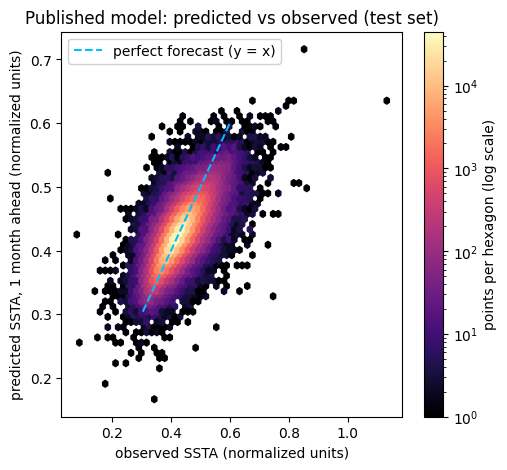

In [5]:
# Overall skill of the published model, from the archived arrays.
# NOTE: the archived arrays are in the normalized units used for training
# (min-max scaled), not °C — the values sit in ~[0, 1]. All comparisons
# below remain valid; absolute values are unitless.
pub_rmse = float(np.sqrt(np.nanmean((pub_preds - pub_obs) ** 2)))
print(f"Published GraphSAGE SSTA test RMSE: {pub_rmse:.3f} (normalized units)")

plt.figure(figsize=(5.5, 5))
lo = np.nanpercentile(pub_obs, 0.1)
hi = np.nanpercentile(pub_obs, 99.9)
plt.hexbin(pub_obs.ravel(), pub_preds.ravel(), gridsize=60, cmap="magma",
           bins="log", mincnt=1)
# Identity line y = x: a perfect forecast would put every point on it.
# Drawn in a colour that stays visible both over the dark hexbin AND on the
# white legend background (a white line would vanish in the legend).
plt.plot([lo, hi], [lo, hi], "--", c="deepskyblue", lw=1.5,
         label="perfect forecast (y = x)")
plt.xlabel("observed SSTA (normalized units)")
plt.ylabel("predicted SSTA, 1 month ahead (normalized units)")
plt.title("Published model: predicted vs observed (test set)")
plt.legend(loc="upper left", framealpha=0.9)
plt.colorbar(label="points per hexagon (log scale)"); plt.show()

Three things to read off this scatter — each one a preview of a theme that runs through this tutorial:

**1. Regression to the mean.** The bright ridge of the cloud tilts *shallower* than the dashed perfect-forecast line: large observed anomalies are systematically under-predicted, and large negative ones over-predicted. The model hedges toward the mean at both tails — a direct consequence of MSE training on imbalanced data, and precisely the behaviour that limits marine-heatwave-relevant skill. This is one of the motivations for future work on different loss functions, and we will return to it in the exercises.

**2. Units.** The values sit in roughly [0, 1] rather than °C: the archived arrays are in the normalized units used for training (min–max scaling), with the zero-anomaly point near ~0.42 rather than 0.5 — the warm tail of the anomaly distribution is longer than the cold tail, so the scaling is asymmetric. Everything we conclude from this plot survives the rescaling.

**3. Test values escape the training range.** Look at the far right of the x-axis: observed values *above 1.0*. Under min–max scaling fitted on the training period, that means the test period contains anomalies **outside the entire historical range the model learned from** — and the model's predictions for those points fall far short. This is non-stationarity made visible: in a warming ocean, record-shattering anomalies keep landing beyond the training distribution, exactly where forecast skill matters most. Keep this plot in mind when we discuss limitations at the end.

The paper's full implementation, trained checkpoints and grid-to-graph converter remain available from the Zenodo records listed in [Data Description](#data-description) as take-home material — we won't need them in this session. (The published checkpoint cannot be run in this notebook anyway: it was trained on the paper's ERA5 data and graph, which require a Copernicus account to rebuild — see [From Prototype to Practice](#prototype-to-practice).) If you are in a hurry or on slow hardware, Section 6 provides the tutorial's own pre-trained checkpoint and a `TRAIN_FROM_SCRATCH` switch.

<a name="m2"></a>
## 2 · Preprocessing: from grid to analysis-ready anomalies

Following the published work, we:

1. **Subset latitudes to 64°S–62°N**, excluding the polar oceans. Poleward of these latitudes the ocean is seasonally or permanently covered by sea ice; where ice is present, the reported SST is constrained to remain near the seawater freezing point (approximately −1.8 °C). The resulting time series therefore exhibit artificially low variance, and their anomalies reflect changes in ice cover rather than in ocean heat content — characteristics that would distort both the correlation-based graph construction (Section 4) and model training. The same spatial domain is used in the published study, which keeps the results directly comparable. Even with this exclusion, residual ice-edge artefacts persist at the southern boundary of the domain; we will encounter them again when visualising the graph.
2. **Restrict to a well-observed period** (1950 onward).
3. **Compute anomalies** (SSTA) by removing the monthly climatology over a **1980–2009 baseline, derived from the training period only**. Deriving the climatology from the training period alone ensures that no validation- or test-period observations enter the preprocessing of inputs or targets. This departs from the current WMO standard normal (1991–2020), which would extend beyond the training period; one consequence is that anomalies in later years carry a larger positive mean, reflecting the warming trend. Marine heatwaves are *anomaly* events — a marine heatwave in the Tasman Sea and one in the North Sea have very different absolute temperatures but comparable anomalies. Removing the seasonal cycle is what makes the forecasting problem non-trivial: otherwise the model just learns that "summer is warm".

Formally, the anomaly at location $s$ and month $t$ is

$$\text{SSTA}(s, t) \;=\; \text{SST}(s, t) \;-\; \overline{\text{SST}}_{m(t)}(s),$$

where $\overline{\text{SST}}_{m(t)}(s)$ denotes the 1980–2009 mean at location $s$ for calendar month $m(t)$.

In [6]:
# Steps 1 and 2: spatial subset to 64°S–62°N (excluding the sea-ice-affected
# polar oceans; see the justification above) and temporal restriction to the
# well-observed modern period. Note that the ERSST latitude coordinate is
# ordered north to south, hence slice(62, -64).
sst = ds["sst"].sel(lat=slice(62, -64), time=slice("1950-01-01", None))
sst = sst.sortby("lat")

# Step 3: monthly climatology over the 1980–2009 baseline — the most recent
# 30-year normal lying entirely WITHIN the training period (train ends 2009-12),
# so no validation- or test-period observations enter the preprocessing.
clim = sst.sel(time=slice("1980-01-01", "2009-12-31")).groupby("time.month").mean("time")
ssta = sst.groupby("time.month") - clim

print("Grid:", dict(ssta.sizes))
print("Period:", str(ssta.time.values[0])[:7], "to", str(ssta.time.values[-1])[:7])

Grid: {'time': 921, 'lat': 64, 'lon': 180}
Period: 1950-01 to 2026-09


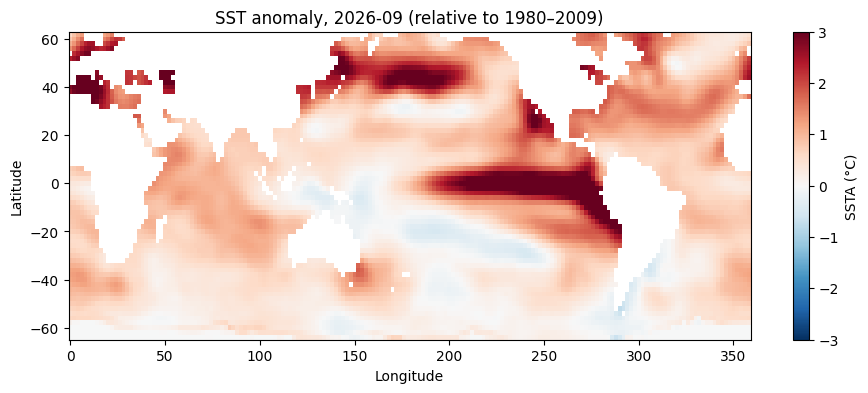

In [7]:
# Quick look: the most recent month's anomaly field
fig, ax = plt.subplots(figsize=(11, 4))
last = ssta.isel(time=-1)
pc = ax.pcolormesh(last.lon, last.lat, last, cmap="RdBu_r", vmin=-3, vmax=3)
plt.colorbar(pc, label="SSTA (°C)")
ax.set_title(f"SST anomaly, {str(last.time.values)[:7]} (relative to 1980–2009)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

### From grid cells to graph nodes

Each **ocean grid cell becomes a node**. We drop land cells, and (to keep the execution fast) subsample every second longitude — this roughly halves the node count with little loss of large-scale structure. Note, that node reduction could be done differently, for example by removing highly spatially-correlated pixels; try that as an exercise at the end.

In [8]:
# Land/ice mask: keep cells with no missing values over the whole period
sub = ssta.isel(lon=slice(0, None, 2))                 # every 2nd longitude
mask = sub.notnull().all("time")
lats2d, lons2d = xr.broadcast(sub.lat, sub.lon)

X = sub.values                                          # [T, nlat, nlon]
T = X.shape[0]
node_idx = np.argwhere(mask.values)                     # ocean cells
X_nodes = np.stack([X[:, i, j] for i, j in node_idx], axis=1).astype(np.float32)  # [T, N]
node_lat = np.array([float(sub.lat[i]) for i, j in node_idx])
node_lon = np.array([float(sub.lon[j]) for i, j in node_idx])
N = X_nodes.shape[1]
print(f"{N} ocean nodes, {T} months")

4349 ocean nodes, 921 months


<a name="m3"></a>
## 3 · Train / validation / test split — **by time**

With time series you must split chronologically, never randomly: a random split leaks future information into training (adjacent months are highly correlated). We also compute the correlation graph **only from training data** — computing it on the full record would leak test-period statistics into the model structure.

In [9]:
time_index = ssta.time.to_index()
t_train_end = time_index.searchsorted(np.datetime64("2010-01-01"))
t_val_end   = time_index.searchsorted(np.datetime64("2016-01-01"))

print(f"train: {time_index[0]:%Y-%m} … {time_index[t_train_end-1]:%Y-%m}  ({t_train_end} months)")
print(f"val:   {time_index[t_train_end]:%Y-%m} … {time_index[t_val_end-1]:%Y-%m}")
print(f"test:  {time_index[t_val_end]:%Y-%m} … {time_index[-1]:%Y-%m}")

train: 1950-01 … 2009-12  (720 months)
val:   2010-01 … 2015-12
test:  2016-01 … 2026-09


<a name="m4"></a>
## 4 · Graph construction: encoding teleconnections as edges

This is the conceptual core of the method. In a CNN, information flows only between *spatially adjacent* pixels. But the ocean doesn't work like that: an El Niño anomaly in the equatorial Pacific is statistically linked to conditions off Australia, in the Indian Ocean, and beyond — the so-called **teleconnections**.

A graph lets us wire those long-range dependencies directly into the model. We use the **Pearson correlation** between node time series (computed on training data) to decide which nodes to connect — with a **hybrid budget** per node: its `k_local` most-correlated partners overall (which, SSTA being spatially smooth, are almost always its neighbours), *plus* its `k_tele` most-correlated partners **beyond 30° of separation** (the teleconnections). Without the second rule, local edges would crowd every teleconnection out of a plain top-k contest — neighbouring cells correlate at r ≈ 0.9+, while even a strong ENSO link only reaches r ≈ 0.5–0.7. Setting `k_tele=0` recovers that naïve top-k graph, which the optional exercise below explores.

Formally, let $x_i^t$ denote the SSTA at node $i$ in month $t$. For every pair of nodes we compute the Pearson correlation over the $T_{\text{train}}$ training months,

$$r_{ij} \;=\; \frac{\sum_{t=1}^{T_{\text{train}}}\big(x_i^t - \bar{x}_i\big)\big(x_j^t - \bar{x}_j\big)}{\sqrt{\sum_t \big(x_i^t - \bar{x}_i\big)^2}\;\sqrt{\sum_t \big(x_j^t - \bar{x}_j\big)^2}},$$

and the great-circle-corrected separation

$$d_{ij} \;=\; \sqrt{\big(\Delta\lambda_{ij}\,\cos\bar{\varphi}_{ij}\big)^2 + \Delta\varphi_{ij}^2},$$

where $\Delta\lambda_{ij}$ and $\Delta\varphi_{ij}$ are the longitude and latitude differences of the pair and $\bar{\varphi}_{ij}$ is their mean latitude. Each node then keeps edges to its most strongly correlated partners by $|r_{ij}|$ — `k_local` of them overall and `k_tele` among those with $d_{ij} > 30°$ — subject to the correlation thresholds given in the function below, and the edge set is symmetrised.

> Think of it as the GNN analogue of choosing predictors by correlation maps except here the model then *learns* how to combine information along those edges.

In [10]:
def build_correlation_graph(X_train, node_lat, node_lon,
                            k_local=8, k_tele=4,
                            min_dist_deg=30,
                            min_abs_corr=0.5, min_tele_corr=0.35):
    """Hybrid correlation graph.

    Each node gets edges to its k_local most-correlated partners overall
    (typically nearby, kept if |r| >= min_abs_corr), plus its k_tele
    most-correlated partners beyond min_dist_deg equivalent degrees
    (~111 km each) of great-circle separation
    (teleconnections, kept if |r| >= min_tele_corr).
    k_tele=0 recovers the naive top-k graph.

    X_train: [T, N] anomalies. Returns (edge_index [2, E], corr matrix).
    """
    Xc = X_train - X_train.mean(axis=0, keepdims=True)
    Xc /= (Xc.std(axis=0, keepdims=True) + 1e-8)
    # Columns of Xc are standardised, so this inner product over the training
    # months equals the Pearson correlation r_ij defined above.
    C = (Xc.T @ Xc) / Xc.shape[0]
    np.fill_diagonal(C, 0.0)
    A = np.abs(C)

    # Pairwise approximate great-circle distance, in "equivalent degrees"
    # (1 unit ~ 111 km), with dateline wrap. Longitude differences are scaled
    # by cos(latitude): meridians converge toward the poles, so 30 deg of raw
    # longitude at 60N is only ~1,670 km -- half its equatorial span. Without
    # this scaling, physically local zonal edges at high latitude would be
    # misclassified as "long-range", and the k_tele rule would use an
    # inconsistent notion of "far" across latitudes.
    dlon = np.abs(node_lon[:, None] - node_lon[None, :])
    dlon = np.minimum(dlon, 360 - dlon)
    coslat = np.cos(np.deg2rad(0.5 * (node_lat[:, None] + node_lat[None, :])))
    dlat = np.abs(node_lat[:, None] - node_lat[None, :])
    dist = np.sqrt((dlon * coslat)**2 + dlat**2)

    src, dst = [], []
    for i in range(A.shape[0]):
        for j in np.argsort(-A[i])[:k_local]:                # best overall
            if A[i, j] >= min_abs_corr:
                src.append(i); dst.append(int(j))
        if k_tele > 0:
            far = np.where(dist[i] > min_dist_deg)[0]        # best far-field
            far = far[np.argsort(-A[i, far])][:k_tele]
            for j in far:
                if A[i, j] >= min_tele_corr:
                    src.append(i); dst.append(int(j))
    edge_index = np.array([src + dst, dst + src])            # symmetrize
    edge_index = np.unique(edge_index.T, axis=0).T
    return torch.tensor(edge_index, dtype=torch.long), C

edge_index, C = build_correlation_graph(
    X_nodes[:t_train_end], node_lat, node_lon)
print(f"{edge_index.shape[1]} directed edges "
      f"({edge_index.shape[1]/N:.1f} per node on average)")

68786 directed edges (15.8 per node on average)


14235 of 34393 undirected edges are long-range (>30° equivalent, ~3,300 km)


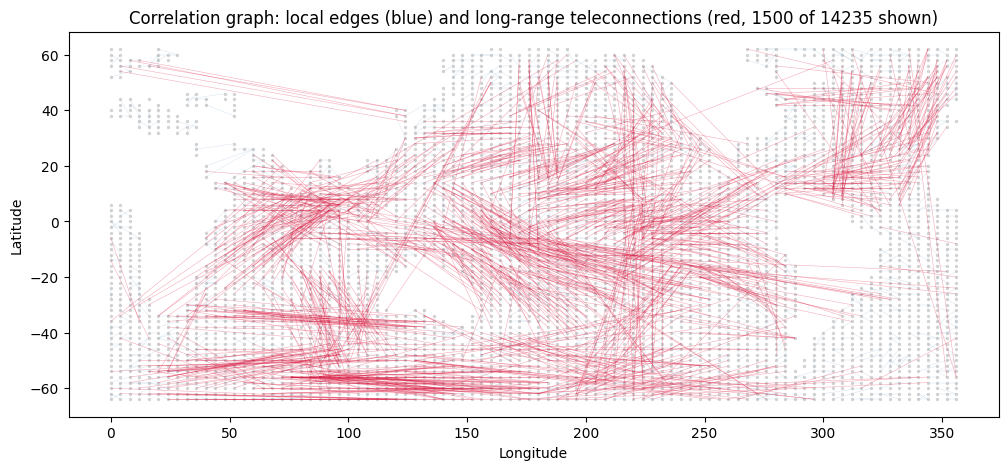

In [11]:
# Visualize the graph: local edges in blue, long-range teleconnections in red.
# We draw each undirected edge once and SAMPLE both groups — the default graph
# has ~16k teleconnection edges, and drawing them all saturates the map in red.
ei = edge_index.numpy()
und = ei[:, ei[0] < ei[1]]                                  # each undirected edge once

# Same cos(latitude)-scaled distance as in build_correlation_graph, so the
# red/blue split here matches the "far" the k_tele rule actually used.
lon_d = np.abs(node_lon[und[0]] - node_lon[und[1]])
lon_d = np.minimum(lon_d, 360 - lon_d)                      # wrap around dateline
coslat = np.cos(np.deg2rad(0.5 * (node_lat[und[0]] + node_lat[und[1]])))
lat_d = np.abs(node_lat[und[0]] - node_lat[und[1]])
approx_deg = np.sqrt((lon_d * coslat)**2 + lat_d**2)        # ~111 km per unit
long_range = approx_deg > 30                                # >~3,300 km

n_long, n_all = int(long_range.sum()), und.shape[1]
print(f"{n_long} of {n_all} undirected edges are long-range (>30° equivalent, ~3,300 km)")

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(node_lon, node_lat, s=2, c="lightgray", zorder=1)
rng_ = np.random.default_rng(0)

def draw(idx, n_max, **style):
    shown = rng_.choice(idx, size=min(n_max, len(idx)), replace=False)
    for e in shown:
        i, j = und[0, e], und[1, e]
        if abs(node_lon[i] - node_lon[j]) < 180:            # skip dateline-wrapping lines
            ax.plot([node_lon[i], node_lon[j]], [node_lat[i], node_lat[j]], **style)
    return len(shown)

# local edges: faint background texture
draw(np.where(~long_range)[0], 2000, lw=0.3, c="steelblue", alpha=0.25, zorder=2)
# long-range teleconnections: a sample, kept thin so hubs and bundles stay visible
n_shown = draw(np.where(long_range)[0], 1500, lw=0.4, c="crimson", alpha=0.35, zorder=3)

ax.set_title(f"Correlation graph: local edges (blue) and long-range teleconnections "
             f"(red, {n_shown} of {n_long} shown)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

**Exercise 4.1** — Rebuild the graph with `min_tele_corr=0.6`. What happens to the long-range edges? And with `k_local=20, k_tele=0`?

**Exercise 4.2** — Pick a node in the central equatorial Pacific and plot a map of its correlation row `C[i]`. You have just reproduced a classic ENSO teleconnection map.

**Exercise 4.3** — Why did we scale longitude differences by cos(latitude) in the distance metric? What would go wrong at 60°N without it — and which edges in the map above would be mislabelled? (Hint: how many kilometres is 30° of longitude at the equator vs at 60°N? Even with the scaling, a few "long-range" edges survive `k_tele=0` along the southern edge of the domain — inspect the SSTA time series there and explain why their correlations are so high.)

Optional exercise:
---
### Naïve vs hybrid graph construction: how much skill do teleconnections buy?

The graph above was built with a **hybrid** rule: each node connects to its `k_local` most-correlated partners overall, *plus* its `k_tele` most-correlated partners beyond 30° of separation.

Why the second rule? Try the naïve version and see for yourself:

1. **Build a naïve top-k graph.** Call `build_correlation_graph` with `k_tele=0` (keeping `k_local=8`), and re-plot the edges. Where do all the connections go?
2. **Diagnose it.** Compute the fraction of edges spanning more than 30°. SSTA fields are spatially smooth, so neighbouring cells correlate at r ≈ 0.9+, while even a strong ENSO teleconnection only reaches r ≈ 0.5–0.7. What does that imply about which edges win a top-k contest — and what kind of model (that you already know from computer vision) does the resulting graph reproduce?
3. **Measure the difference.** Retrain the GraphSAGE model once on each graph, keeping everything else fixed, and compare the two skill maps from Section 7. Look specifically at ENSO-influenced regions (equatorial Pacific, Indian Ocean, the extratropical Pacific horseshoe): does the hybrid graph add skill *there*, or everywhere, or nowhere?
4. **Think about it.** If teleconnection edges help, why might that be — what information reaches a node off New Zealand through a Pacific edge that it cannot get from its immediate neighbours? And if they *don't* help much at 1-month lead, at what lead time would you expect them to matter more, given that teleconnection signals take months to propagate?

---

### Forecasting samples

Each training sample is a snapshot of the whole graph: node features are the **last 12 months of SSTA** at that node, and the target is **next month's SSTA**.

In [12]:
L = 12  # months of history per node

def make_samples(X, t_start, t_end):
    xs, ys = [], []
    for t in range(max(t_start, L), t_end):
        xs.append(X[t - L:t].T)                          # [N, L]
        ys.append(X[t])                                  # [N]
    return (torch.tensor(np.stack(xs)), torch.tensor(np.stack(ys)))

X_tr, y_tr = make_samples(X_nodes, 0,            t_train_end)
X_va, y_va = make_samples(X_nodes, t_train_end,  t_val_end)
X_te, y_te = make_samples(X_nodes, t_val_end,    T)
print("train / val / test samples:", X_tr.shape[0], X_va.shape[0], X_te.shape[0])

train / val / test samples: 708 72 129


<a name="m5"></a>
## 5 · Baselines first

Two baselines we aim to beat:

- **Persistence** — next month's anomaly equals this month's. Deceptively strong at 1-month lead because SSTA is highly autocorrelated (the ocean has thermal memory).
- **Climatology** — the anomaly is zero (i.e., forecast the seasonal mean). Strong at long leads.

A model that doesn't clearly beat persistence at short lead has learned nothing useful.

In [13]:
def rmse(a, b): return float(torch.sqrt(((a - b) ** 2).mean()))

rmse_persist_test = rmse(X_te[:, :, -1], y_te)
rmse_clim_test    = rmse(torch.zeros_like(y_te), y_te)
print(f"Persistence RMSE (test): {rmse_persist_test:.3f} °C")
print(f"Climatology RMSE (test): {rmse_clim_test:.3f} °C")

Persistence RMSE (test): 0.344 °C
Climatology RMSE (test): 0.744 °C


<a name="m6"></a>
## 6 · The GraphSAGE model

**GraphSAGE** ([Hamilton et al., 2017](https://arxiv.org/abs/1706.02216)) updates each node by combining its own features with an **aggregate (mean) of its neighbours' features**, passed through learned weight matrices:

$$h_i^{(l+1)} = \sigma\left( W_1 h_i^{(l)} + W_2 \cdot \text{mean}_{j \in \mathcal{N}(i)} h_j^{(l)} \right)$$

![One GraphSAGE layer at node i](https://raw.githubusercontent.com/vetrovav/marine-heatwave-forecasting-tutorial/main/notebook/gnn_schematic.png)

The figure traces this update concretely for the first layer ($l = 0$). Initially, each node $i$ stores $h_i^{(0)} = (x_i^{t-11}, \ldots, x_i^{t}) \in \mathbb{R}^{12}$ — the last twelve months of SSTA at that location, in the notation of Section 4, and nothing else: coordinates are not inputs, and spatial structure enters the model only through the edges. One layer then proceeds in three steps. (1) **Message:** every neighbour $j \in \mathcal{N}(i)$ sends its current vector $h_j^{(0)}$ along the connecting edge. (2) **Aggregation:** node $i$ averages the incoming vectors; the mean is indifferent to the order and the number of neighbours, so the same rule serves every node of the irregular ocean graph. (3) **Update:** the aggregate is combined with the node's own vector through the two learned weight matrices, producing $h_i^{(1)} \in \mathbb{R}^{128}$; a second application of the same rule yields $h_i^{(2)}$, and a final linear layer maps it to a single number — the predicted SSTA at node $i$ one month ahead.

Stacking two layers means every node sees information from its neighbours' neighbours — so with teleconnection edges, a node off New Zealand can directly ingest equatorial Pacific information. In the paper, GraphSAGE outperformed GCN, GAT and relational GCN variants for this task, and its *inductive* formulation means the learned model doesn't depend on one fixed graph — you can rebuild the graph and reuse the weights.

![Two layers of message passing: the receptive field of node i](https://raw.githubusercontent.com/vetrovav/marine-heatwave-forecasting-tutorial/main/notebook/gnn_receptive_field.png)

> **Shortcut for slow hardware:** the training cell below has a `TRAIN_FROM_SCRATCH` switch. Leave it `True` to train yourself (~5 min on a free Colab GPU); set it `False` to download a pre-trained tutorial checkpoint (trained with this exact notebook) and continue straight to the evaluation. The cell shows a progress bar and reports its total runtime, and warns you explicitly if it is about to train on CPU.

In [14]:
class SAGEForecaster(nn.Module):
    def __init__(self, in_dim, hidden=128, layers=2, dropout=0.2):
        super().__init__()
        self.convs = nn.ModuleList()
        d = in_dim
        for _ in range(layers):
            self.convs.append(SAGEConv(d, hidden))
            d = hidden
        self.head = nn.Linear(hidden, 1)
        self.act = nn.ReLU(); self.dropout = nn.Dropout(dropout)

    def forward(self, x, edge_index):
        for conv in self.convs:
            x = self.dropout(self.act(conv(x, edge_index)))
        return self.head(x).squeeze(-1)

model = SAGEForecaster(in_dim=L).to(device)
edge_index_d = edge_index.to(device)
sum(p.numel() for p in model.parameters())

36225

In [15]:
TRAIN_FROM_SCRATCH = True   # <-- set to False to skip training on slow hardware

# Pre-trained tutorial checkpoint (~150 kB), hosted in the tutorial repository;
# trained with this exact notebook, i.e. on anomalies defined against the
# training-period (1980-2009) climatology.
CKPT_URL  = ("https://raw.githubusercontent.com/vetrovav/"
             "marine-heatwave-forecasting-tutorial/main/notebook/tutorial_checkpoint_trainclim.pt")
CKPT_PATH = "tutorial_checkpoint_trainclim.pt"

if TRAIN_FROM_SCRATCH:
    import time
    from tqdm.auto import tqdm   # progress bar (preinstalled on Colab)

    if device.type == "cpu":
        print("No GPU detected: training will run on CPU, typically several times")
        print("slower than the ~5 min it takes on a free Colab GPU. Options:")
        print("  - Colab: Runtime > Change runtime type > T4 GPU, then rerun all cells")
        print("  - or set TRAIN_FROM_SCRATCH = False above to load the pre-trained")
        print("    tutorial checkpoint and skip training entirely.\n")

    t_start = time.time()
    EPOCHS = 30
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    loss_fn = nn.MSELoss()
    best_val, best_state = float("inf"), None

    for epoch in tqdm(range(EPOCHS), desc="training", unit="epoch"):
        model.train()
        perm = torch.randperm(X_tr.shape[0])
        tr_loss = 0.0
        for i in perm:
            opt.zero_grad()
            pred = model(X_tr[i].to(device), edge_index_d)
            loss = loss_fn(pred, y_tr[i].to(device))
            loss.backward(); opt.step()
            tr_loss += loss.item()
        model.eval()
        with torch.no_grad():
            va = np.mean([loss_fn(model(X_va[i].to(device), edge_index_d),
                                  y_va[i].to(device)).item()
                          for i in range(X_va.shape[0])])
        if va < best_val:
            best_val, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
        if epoch % 5 == 0 or epoch == EPOCHS - 1:
            tqdm.write(f"epoch {epoch:2d} | train MSE {tr_loss/len(perm):.4f} | val MSE {va:.4f}")

    model.load_state_dict(best_state)
    elapsed = time.time() - t_start
    print(f"Loaded best model (val MSE {best_val:.4f}); "
          f"training took {elapsed/60:.1f} min on {device}")
    torch.save(model.state_dict(), CKPT_PATH)   # so you can reload later without retraining
else:
    if not os.path.exists(CKPT_PATH):
        try:
            urllib.request.urlretrieve(CKPT_URL, CKPT_PATH)
        except Exception as e:
            raise RuntimeError(
                "Could not download the tutorial checkpoint - "
                "set TRAIN_FROM_SCRATCH = True and run this cell again.") from e
    model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
    model.eval()
    print("Loaded the pre-trained tutorial checkpoint - training skipped.")

training:   0%|          | 0/30 [00:00<?, ?epoch/s]

epoch  0 | train MSE 0.1348 | val MSE 0.1088
epoch  5 | train MSE 0.1232 | val MSE 0.1217
epoch 10 | train MSE 0.1223 | val MSE 0.1088
epoch 15 | train MSE 0.1217 | val MSE 0.1203
epoch 20 | train MSE 0.1213 | val MSE 0.1063
epoch 25 | train MSE 0.1211 | val MSE 0.1083
epoch 29 | train MSE 0.1211 | val MSE 0.1181
Loaded best model (val MSE 0.1043); training took 1.1 min on cuda


<a name="m7"></a>
## 7 · Evaluation: does the GNN add skill, and *where*?

Let's look at global-average RMSE first, then explore the more interesting question — a **skill map**. Skill relative to persistence:

$$\text{skill}_i = 1 - \frac{\text{RMSE}^{GNN}_i}{\text{RMSE}^{persist}_i}$$

positive where the GNN beats persistence. The paper found enhanced SSTA predictability in regions with persistent currents, and lower skill in equatorial and Antarctic-adjacent waters — check whether you see the same pattern.

In [16]:
model.eval()
with torch.no_grad():
    preds = torch.stack([model(X_te[i].to(device), edge_index_d).cpu()
                         for i in range(X_te.shape[0])])

print(f"GNN RMSE (test):         {rmse(preds, y_te):.3f} °C")
print(f"Persistence RMSE (test): {rmse_persist_test:.3f} °C")
print(f"Climatology RMSE (test): {rmse_clim_test:.3f} °C")

GNN RMSE (test):         0.322 °C
Persistence RMSE (test): 0.344 °C
Climatology RMSE (test): 0.744 °C


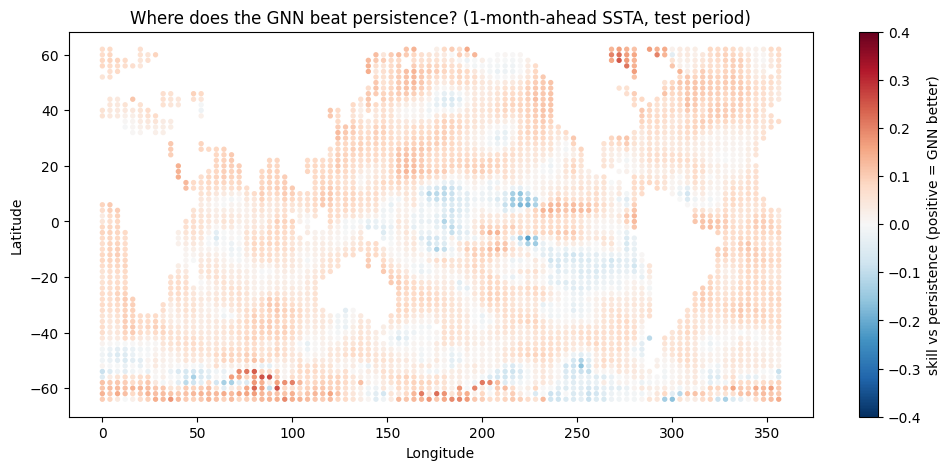

GNN beats persistence at 85% of nodes


In [17]:
# Per-node skill map vs persistence
rmse_gnn_node = torch.sqrt(((preds - y_te) ** 2).mean(0)).numpy()
rmse_per_node = torch.sqrt(((X_te[:, :, -1] - y_te) ** 2).mean(0)).numpy()
skill = 1 - rmse_gnn_node / rmse_per_node

fig, ax = plt.subplots(figsize=(12, 5))
sc = ax.scatter(node_lon, node_lat, c=skill, s=8, cmap="RdBu_r", vmin=-0.4, vmax=0.4)
plt.colorbar(sc, label="skill vs persistence (positive = GNN better)")
ax.set_title("Where does the GNN beat persistence? (1-month-ahead SSTA, test period)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()
print(f"GNN beats persistence at {100*(skill > 0).mean():.0f}% of nodes")

### Marine heatwave hotspots

Marine heatwaves are prolonged extreme warm SSTA events with severe ecological and economic impacts. Skilful SSTA forecasts at known hotspots are a first step toward MHW early warning. Let's inspect forecasts at some famous ones:

- **NE Pacific** — the 2013–2016 "Blob"
- **Tasman Sea** — the 2015/16 and 2017/18 events that devastated aquaculture
- **Western Australia** — the 2011 Ningaloo Niño
- **Niño3.4 region** — ENSO's centre of action

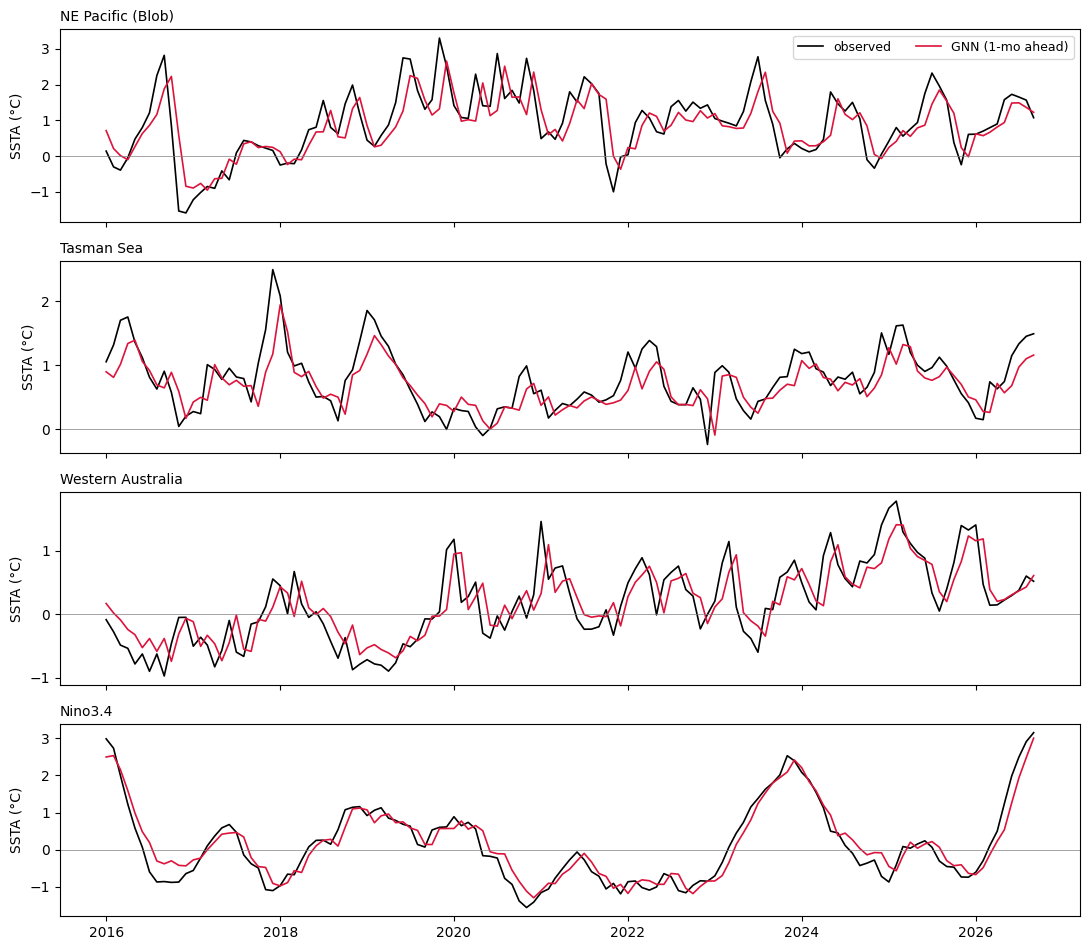

In [18]:
hotspots = {
    "NE Pacific (Blob)":   (45,  215),
    "Tasman Sea":          (-40, 155),
    "Western Australia":   (-28, 112),
    "Nino3.4":             (0,   210),
}

def nearest_node(lat, lon):
    return int(np.argmin((node_lat - lat) ** 2 + (node_lon - lon) ** 2))

test_times = time_index[max(t_val_end, L):][:preds.shape[0]]
fig, axes = plt.subplots(len(hotspots), 1, figsize=(11, 2.4 * len(hotspots)), sharex=True)
for ax, (name, (la, lo)) in zip(axes, hotspots.items()):
    i = nearest_node(la, lo)
    ax.plot(test_times[:len(y_te)], y_te[:, i], c="k", lw=1.2, label="observed")
    ax.plot(test_times[:len(preds)], preds[:, i], c="crimson", lw=1.2, label="GNN (1-mo ahead)")
    ax.axhline(0, c="gray", lw=0.5)
    ax.set_ylabel("SSTA (°C)"); ax.set_title(name, fontsize=10, loc="left")
axes[0].legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

**Exercise 7.1** — Compute skill separately for months where |observed SSTA| > 1 °C (extreme months). Is the model better or worse during extremes? This connects to a key open problem in the paper: imbalanced regression for extreme SSTAs.

<a name="m8"></a>
## 8 · Recursive multi-step forecasting

To forecast beyond one month, the model's own one-month prediction is appended to the input window and the procedure is iterated — the approach used in the published study for SST forecasts of up to two years ahead. Forecast skill is expected to degrade with lead time and to converge toward the climatological error. To obtain representative lead-time statistics rather than a single trajectory, the evaluation below averages over **all initialization months** in the test period that admit a full 12-month verification window, and the model, persistence, and climatology forecasts are verified on **identical sets of target months** at every lead.

initializations:   0%|          | 0/118 [00:00<?, ?init/s]

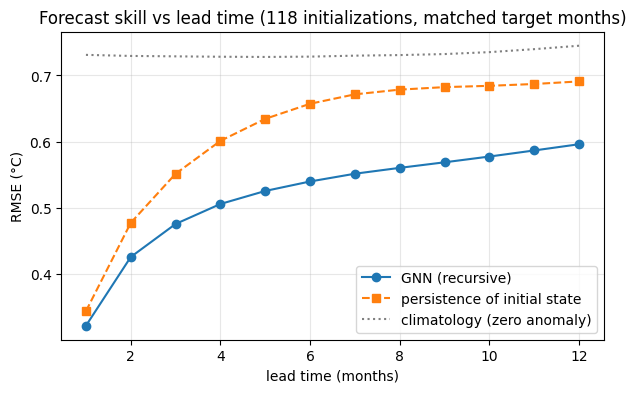

In [19]:
LEADS = 12
model.eval()
from tqdm.auto import tqdm

# All initialization months with LEADS verifying months ahead of them, so that
# every lead is evaluated on the same set of target months for all forecasts.
n_init = X_te.shape[0] - LEADS + 1
sq_gnn  = torch.zeros(LEADS)      # accumulated mean-squared error per lead
sq_per  = torch.zeros(LEADS)
sq_clim = torch.zeros(LEADS)

with torch.no_grad():
    for t0 in tqdm(range(n_init), desc="initializations", unit="init"):
        window = X_te[t0].clone().to(device)
        for h in range(LEADS):
            pred = model(window, edge_index_d).cpu()
            target = y_te[t0 + h]
            sq_gnn[h]  += ((pred - target) ** 2).mean()
            sq_per[h]  += ((X_te[t0][:, -1] - target) ** 2).mean()  # persist initial state
            sq_clim[h] += (target ** 2).mean()                       # zero-anomaly forecast
            window = torch.cat([window[:, 1:], pred.to(device).unsqueeze(1)], dim=1)

leads = range(1, LEADS + 1)
plt.figure(figsize=(7, 4))
plt.plot(leads, torch.sqrt(sq_gnn  / n_init).numpy(), "o-",  label="GNN (recursive)")
plt.plot(leads, torch.sqrt(sq_per  / n_init).numpy(), "s--", label="persistence of initial state")
plt.plot(leads, torch.sqrt(sq_clim / n_init).numpy(), ":", c="gray", label="climatology (zero anomaly)")
plt.xlabel("lead time (months)"); plt.ylabel("RMSE (°C)")
plt.title(f"Forecast skill vs lead time ({n_init} initializations, matched target months)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

<a name="prototype-to-practice"></a>
#  From Prototype to Practice

What separates this tutorial pipeline from an operational MHW early-warning system — and from the published study? Each gap is a concrete direction you can pursue:

1. **Exact reproduction with ERA5.** Register (free) at the [Copernicus Climate Data Store](https://cds.climate.copernicus.eu), install `cdsapi`, store your API key in `~/.cdsapirc`, and request `reanalysis-era5-single-levels-monthly-means` / `sea_surface_temperature`. Everything downstream of the loading cell is unchanged; the paper's [graph converter](https://doi.org/10.5281/zenodo.10702598) provides the exact published graph construction.
2. **From monthly SSTA to MHW events.** Operational MHW definitions (Hobday et al., 2016) work on *daily* data with percentile thresholds. Moving to daily products (e.g., NOAA OISST) raises the data volume ~30× and makes graph construction and training a genuine scaling exercise.
3. **Extremes-aware training.** Replace MSE with a loss that upweights large anomalies (weighted MSE, focal-style regression) and re-examine hotspot skill — the paper identifies imbalanced regression for extreme SSTAs as a key open problem.
4. **Direct multi-step & benchmark yourself.** Train the model to predict lead-3 directly instead of recursively — exactly the setting of the ECML PKDD 2024 *Diving Deep* discovery challenge run by the paper's authors.
5. **Richer node features and temporal modules.** Add static features (lat, lon, basin), extra variables (wind stress, heat fluxes), or combine the GNN spatial layer with an LSTM/temporal-attention encoder over the input window.
6. **Uncertainty.** An operational warning needs probabilities, not point forecasts: ensembles via input perturbation or dropout, or quantile losses, are natural next steps.

<a name="final-discussion-takeaways"></a>
# Final Discussion & Takeaways

**What we built:** an end-to-end GNN forecasting pipeline for global ocean anomalies — data → graph → GraphSAGE → skill maps → recursive forecasts — validated against the baselines that matter and compared against the study's published results.

**Key takeaways:**

* Graphs let a forecasting model exploit **teleconnections** that grid-based convolutional models cannot see; the correlation graph is both a modelling choice and an object of scientific investigation.
* **Baselines.** Persistence is strong at short leads in the ocean; but a skill *map* against persistence is far more informative than one global RMSE number.
* **Extremes are the key.** MSE-trained models regress to the mean exactly where marine heatwave prediction needs the most skill — visible directly in the published predicted-vs-observed scatter. Different loss functions are needed.

<a name="limitations"></a>
### Limitations

* Monthly, ~2° resolution captures large-scale anomaly patterns, not the fine structure or daily timing of individual MHW events.
* The correlation graph is **static and linear**: it is built once from training-period Pearson correlations, so it cannot represent seasonally varying or nonlinear dependencies, and it inherits any non-stationarity — under a warming trend, historical teleconnection statistics may drift. The predicted-vs-observed scatter in Methodology §1 shows this concretely: test-period anomalies exceed the training-period range (normalized values > 1), and the model fails hardest on exactly those record-breaking events.
* Recursive forecasts compound errors; skill at long leads should be interpreted against climatology, not in absolute terms.
* Results in this notebook use ERSSTv5 and a simplified node-reduction scheme, so numbers will differ somewhat from the published ERA5 results — that comparison is itself a useful robustness exercise.

<a name="references"></a>
# References

* Ning, D., Vetrova, V., Bryan, K. R., & Koh, Y. S. (2024). Harnessing the Power of Graph Representation in Climate Forecasting: Predicting Global Monthly Mean Sea Surface Temperatures and Anomalies. *Earth and Space Science*, 11, e2023EA003455. https://doi.org/10.1029/2023EA003455
* Ning, D. (2024a). ERA5 Sea Surface Temperature Grid to Graph Converter. Zenodo. https://doi.org/10.5281/zenodo.10702598
* Ning, D. (2024b). GraphSAGE Model Checkpoints and Results for Sea Surface Temperature and Anomaly Forecasts. Zenodo. https://doi.org/10.5281/zenodo.10702459
* Ning, D. (2024c). GraphSAGE Models for Sea Surface Temperature and Anomaly Forecasts with Auxiliary Functions. Zenodo. https://doi.org/10.5281/zenodo.10702592
* Hamilton, W., Ying, Z., & Leskovec, J. (2017). Inductive representation learning on large graphs. *NeurIPS 30*.
* Hobday, A. J., et al. (2016). A hierarchical approach to defining marine heatwaves. *Progress in Oceanography*, 141, 227–238.
* Huang, B., et al. (2017). Extended Reconstructed Sea Surface Temperature, Version 5 (ERSSTv5). *Journal of Climate*, 30, 8179–8205.
* Hersbach, H., et al. (2020). The ERA5 global reanalysis. *QJRMS*, 146, 1999–2049.